In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
train = pd.read_csv("Train.csv")
test = pd.read_csv("Test.csv")

In [ ]:
train.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [ ]:
train.shape

(8068, 11)

In [ ]:
test.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6,B
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6,A
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6,A
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6,B
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6,A


In [ ]:
test.shape

(2627, 11)

In [ ]:
8068 + 2627

10695

In [ ]:
df = pd.concat([train, test], axis=0, ignore_index=True)

In [ ]:
df.shape

(10695, 11)

In [ ]:
df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10695 entries, 0 to 10694
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               10695 non-null  int64  
 1   Gender           10695 non-null  object 
 2   Ever_Married     10505 non-null  object 
 3   Age              10695 non-null  int64  
 4   Graduated        10593 non-null  object 
 5   Profession       10533 non-null  object 
 6   Work_Experience  9597 non-null   float64
 7   Spending_Score   10695 non-null  object 
 8   Family_Size      10247 non-null  float64
 9   Var_1            10587 non-null  object 
 10  Segmentation     10695 non-null  object 
dtypes: float64(2), int64(2), object(7)
memory usage: 919.2+ KB


In [ ]:
df.describe()

,ID,Age,Work_Experience,Family_Size
count,10695.000000,10695.000000,9597.000000,10247.000000
mean,463468.088640,43.511828,2.619777,2.844052
std,2600.966411,16.774158,3.390790,1.536427
min,458982.000000,18.000000,0.000000,1.000000
25%,461220.500000,30.000000,0.000000,2.000000
50%,463451.000000,41.000000,1.000000,3.000000
75%,465733.500000,53.000000,4.000000,4.000000
max,467974.000000,89.000000,14.000000,9.000000


In [ ]:
df.duplicated().sum()

np.int64(38)

In [ ]:
df.drop_duplicates(inplace = True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

,0
ID,0
Gender,0
Ever_Married,189
Age,0
Graduated,100
Profession,162
Work_Experience,1090
Spending_Score,0
Family_Size,447
Var_1,108


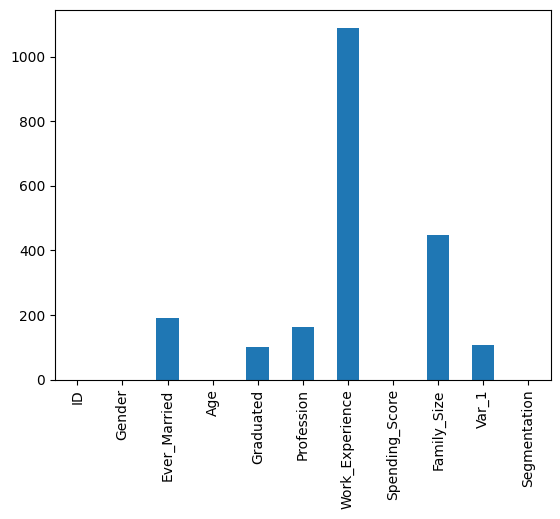

In [ ]:
df.isna().sum().plot(kind = "bar")
plt.show()

In [ ]:
df.shape

(10657, 11)

In [ ]:
df.dtypes

,0
ID,int64
Gender,object
Ever_Married,object
Age,int64
Graduated,object
Profession,object
Work_Experience,float64
Spending_Score,object
Family_Size,float64
Var_1,object


In [ ]:
df.isna().sum()

,0
ID,0
Gender,0
Ever_Married,189
Age,0
Graduated,100
Profession,162
Work_Experience,1090
Spending_Score,0
Family_Size,447
Var_1,108


In [ ]:
df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [ ]:
column = [col for col in df.select_dtypes("object")]
column

['Gender',
 'Ever_Married',
 'Graduated',
 'Profession',
 'Spending_Score',
 'Var_1',
 'Segmentation']

In [ ]:
from sklearn.impute import SimpleImputer

In [ ]:
most_freq_impute = SimpleImputer(missing_values=np.nan , strategy="most_frequent")
for col in column:
    df[[col]] = most_freq_impute.fit_transform(df[[col]])

In [ ]:
df.isna().sum()

,0
ID,0
Gender,0
Ever_Married,0
Age,0
Graduated,0
Profession,0
Work_Experience,1090
Spending_Score,0
Family_Size,447
Var_1,0


Skew: 1.3228953366382827


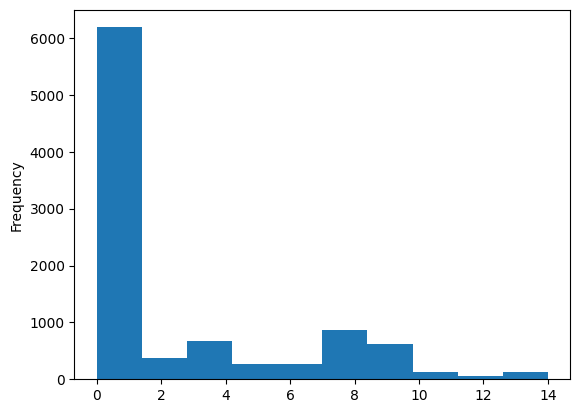

In [ ]:
print(f"Skew: {df["Work_Experience"].skew()}")
df["Work_Experience"].plot(kind="hist")
plt.show()

In [ ]:
median_impute = SimpleImputer(missing_values=np.nan , strategy="median")

In [ ]:
df[["Work_Experience"]] = median_impute.fit_transform(df[["Work_Experience"]])

Skew: 1.012619646562444


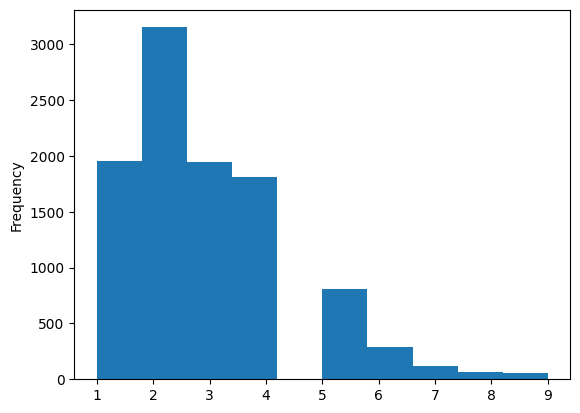

In [ ]:
print(f"Skew: {df["Family_Size"].skew()}")
df["Family_Size"].plot(kind="hist")
plt.show()

In [ ]:
df[["Family_Size"]] = median_impute.fit_transform(df[["Family_Size"]])

In [ ]:
df.isna().sum()

,0
ID,0
Gender,0
Ever_Married,0
Age,0
Graduated,0
Profession,0
Work_Experience,0
Spending_Score,0
Family_Size,0
Var_1,0


In [ ]:
df.drop("ID" , inplace = True , axis = 1)

In [ ]:
df.head(15)

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,Female,Yes,38,Yes,Engineer,1.0,Average,3.0,Cat_4,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,Female,Yes,40,Yes,Entertainment,1.0,High,6.0,Cat_6,A
5,Male,Yes,56,No,Artist,0.0,Average,2.0,Cat_6,C
6,Male,No,32,Yes,Healthcare,1.0,Low,3.0,Cat_6,C
7,Female,No,33,Yes,Healthcare,1.0,Low,3.0,Cat_6,D
8,Female,Yes,61,Yes,Engineer,0.0,Low,3.0,Cat_7,D
9,Female,Yes,55,Yes,Artist,1.0,Average,4.0,Cat_6,C


In [ ]:
column = [col for col in df.select_dtypes("object")]

In [ ]:
for col in column:
    print(f"Number of Unique Value for {col}: {df[col].nunique()}")
    print(f"Unique Value for {col}: {df[col].unique()}")
    print()
    print("*" * 50)

Number of Unique Value for Gender: 2
Unique Value for Gender: ['Male' 'Female']

**************************************************
Number of Unique Value for Ever_Married: 2
Unique Value for Ever_Married: ['No' 'Yes']

**************************************************
Number of Unique Value for Graduated: 2
Unique Value for Graduated: ['No' 'Yes']

**************************************************
Number of Unique Value for Profession: 9
Unique Value for Profession: ['Healthcare' 'Engineer' 'Lawyer' 'Entertainment' 'Artist' 'Executive'
 'Doctor' 'Homemaker' 'Marketing']

**************************************************
Number of Unique Value for Spending_Score: 3
Unique Value for Spending_Score: ['Low' 'Average' 'High']

**************************************************
Number of Unique Value for Var_1: 7
Unique Value for Var_1: ['Cat_4' 'Cat_6' 'Cat_7' 'Cat_3' 'Cat_1' 'Cat_2' 'Cat_5']

**************************************************
Number of Unique Value for Segmentation: 4


In [ ]:
from sklearn.preprocessing import LabelEncoder , OneHotEncoder

In [45]:
ohe = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)
for col in ["Gender", "Ever_Married", "Graduated", "Spending_Score"]:
    ce = ohe.fit_transform(df[[col]])
    frame = pd.DataFrame(ce, columns=ohe.get_feature_names_out([col]))
    frame.index = df.index
    df = pd.concat([df.drop(columns=[col]), frame], axis=1)

In [46]:
df.head()

,Age,Profession,Work_Experience,Family_Size,Var_1,Segmentation,Gender_Female,Gender_Male,Ever_Married_No,Ever_Married_Yes,Graduated_No,Graduated_Yes,Spending_Score_Average,Spending_Score_High,Spending_Score_Low
0,22,Healthcare,1.0,4.0,Cat_4,D,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,38,Engineer,1.0,3.0,Cat_4,A,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
2,67,Engineer,1.0,1.0,Cat_6,B,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
3,67,Lawyer,0.0,2.0,Cat_6,B,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,40,Entertainment,1.0,6.0,Cat_6,A,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [50]:
le = LabelEncoder()

for col in ["Profession", "Var_1"]:
    df[col] = le.fit_transform(df[[col]])


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [51]:
df.head()

,Age,Profession,Work_Experience,Family_Size,Var_1,Segmentation,Gender_Female,Gender_Male,Ever_Married_No,Ever_Married_Yes,Graduated_No,Graduated_Yes,Spending_Score_Average,Spending_Score_High,Spending_Score_Low
0,22,5,1.0,4.0,3,D,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,38,2,1.0,3.0,3,A,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
2,67,2,1.0,1.0,5,B,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
3,67,7,0.0,2.0,5,B,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,40,3,1.0,6.0,5,A,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [52]:
X = df.drop("Segmentation" , axis = 1)
y = df["Segmentation"]

In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [56]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [67]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(class_weight="balanced")
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced')

In [68]:
y_pred = model.predict(X_test)

In [69]:
from sklearn.metrics import accuracy_score , classification_report , confusion_matrix
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")
print()
print("*" *50)
print()
report = classification_report(y_test, y_pred)
print(f"classification_report:\n {report}")

Accuracy: 0.4629455909943715

**************************************************

classification_report:
               precision    recall  f1-score   support

           A       0.41      0.41      0.41       570
           B       0.32      0.19      0.24       488
           C       0.42      0.57      0.49       447
           D       0.60      0.65      0.62       627

    accuracy                           0.46      2132
   macro avg       0.44      0.45      0.44      2132
weighted avg       0.45      0.46      0.45      2132



In [70]:
cm = confusion_matrix(y_test, y_pred)
print(f"confusion_matrix:\n {cm}")

confusion_matrix:
 [[233  80 128 129]
 [147  93 170  78]
 [ 69  63 255  60]
 [119  52  50 406]]


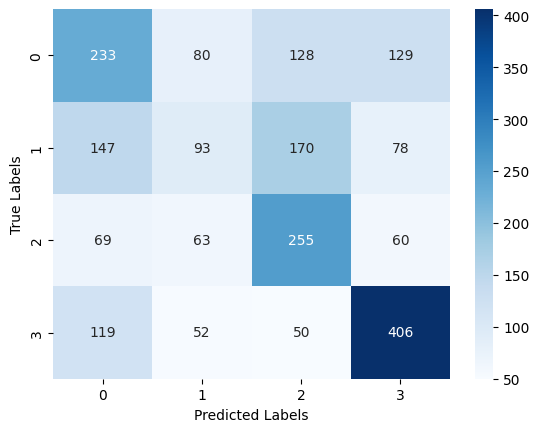

In [71]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()